In [1]:
import dask.dataframe as dd
import pandas as pd
import os
from dask import delayed
import matplotlib.pyplot as plt
import seaborn as sns

/Users/parikshitnarang/Library/Python/3.9/lib/python/site-packages/dask/dataframe/_pyarrow_compat.py:21: UserWarning: You are using pyarrow version 10.0.1 which is known to be insecure. See https://www.cve.org/CVERecord?id=CVE-2023-47248 for further details. Please upgrade to pyarrow>=14.0.1 or install pyarrow-hotfix to patch your current version.
  warnings.warn(
/Users/parikshitnarang/Library/Python/3.9/lib/python/site-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


In [2]:
def load_processed_data(base_dir):
    all_data = []
    for year_folder in os.listdir(base_dir):
        if not year_folder.startswith('year='):
            continue
        
        year_dir = os.path.join(base_dir, year_folder)
        
        year_files = [f for f in os.listdir(year_dir) if f.endswith('.parquet')]

        for file in year_files:
            file_path = os.path.join(year_dir, file)
            try:
                df = pd.read_parquet(file_path)  
                delayed_df = delayed(pd.read_parquet)(file_path)
                all_data.append(delayed_df)
            except Exception as e:
                print(f"Skipping file {file_path} due to error: {e}")
    
    full_df = dd.from_delayed(all_data)
    return full_df

In [3]:
base_dir = "../../preprocessed"
df_all = load_processed_data(base_dir)

df_all = df_all.compute()

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [6]:
def plot_missing_data(df):
    plt.figure(figsize=(12, 6))
    sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
    plt.title("Missing Data Heatmap", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig("missing_data_heatmap.png")  
    plt.close()  

In [7]:
def plot_numerical_feature_distributions(df):
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for idx, col in enumerate(numerical_features):
        if idx < len(axes):
            df[col].plot(kind='hist', ax=axes[idx], bins=50, alpha=0.7, color=sns.color_palette("viridis")[1], edgecolor='black')
            axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel(col, fontsize=10)
            axes[idx].set_ylabel('Frequency', fontsize=10)
            axes[idx].grid(alpha=0.3)

    for idx in range(len(numerical_features), len(axes)):
        axes[idx].axis('off')

    plt.tight_layout()
    plt.savefig("numerical_feature_distributions.png") 
    plt.close() 

ValueError: cannot reindex on an axis with duplicate labels

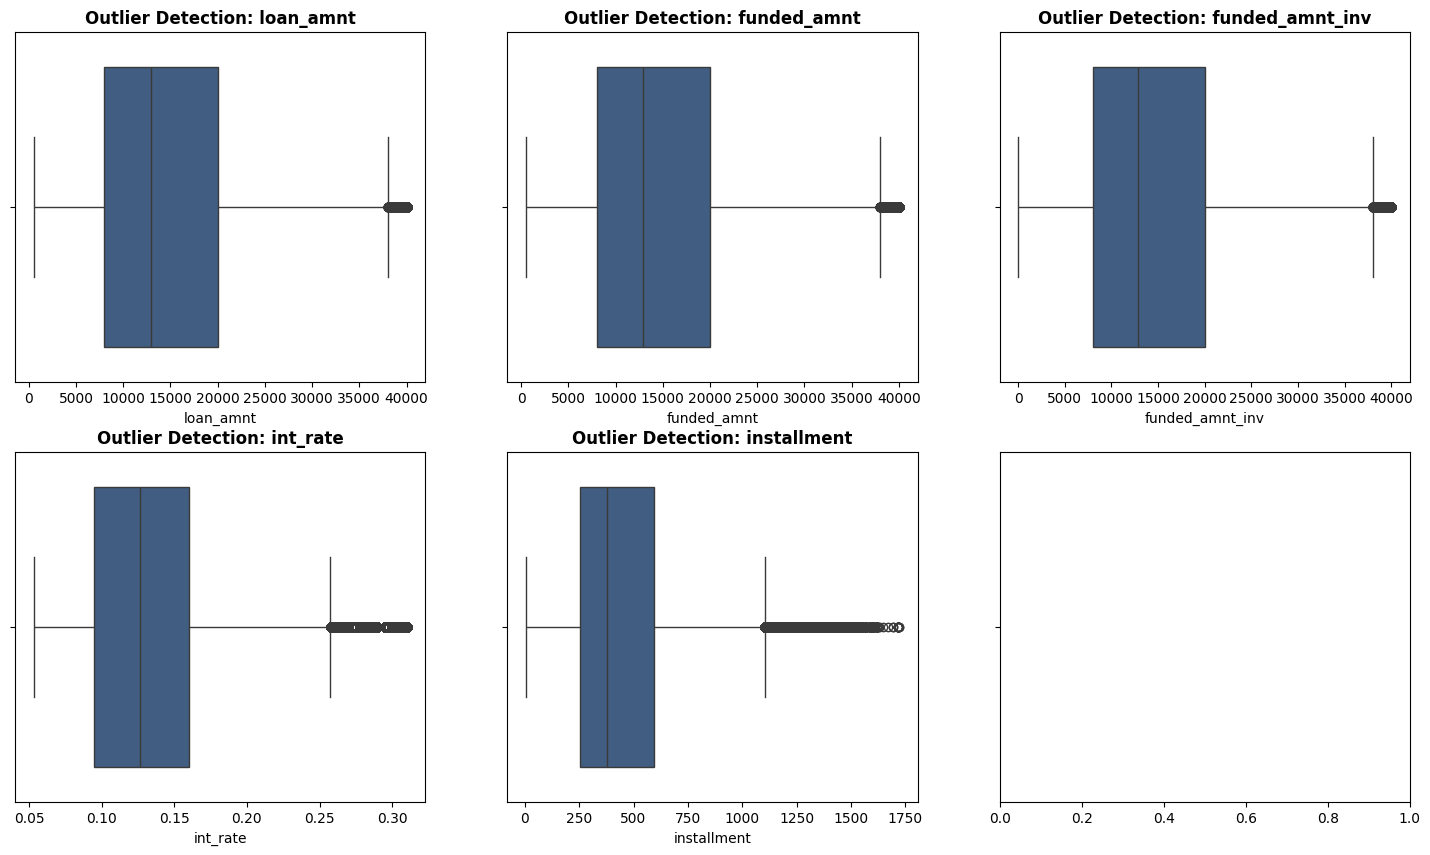

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_outlier_detection(df):
    df = df.loc[:, ~df.columns.duplicated()]
    
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for idx, col in enumerate(numerical_features):
        if idx < len(axes):
            sns.boxplot(x=df[col], ax=axes[idx], color=sns.color_palette("viridis")[1])
            axes[idx].set_title(f'Outlier Detection: {col}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel(col, fontsize=10)

    plt.tight_layout()
    plt.savefig("outlier_detection.png")
    plt.close()  

plot_outlier_detection(df_all)

In [9]:
def plot_correlation_matrix(df):
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
    plt.figure(figsize=(12, 10))
    correlation_matrix = df[numerical_features].corr()
    sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap="coolwarm", 
                square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
    plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig("correlation_matrix.png")
    plt.close()  

In [10]:
def plot_categorical_feature_distributions(df):
    categorical_features = df.select_dtypes(include=['object', 'category']).columns
    for col in categorical_features:
        plt.figure(figsize=(8, 6))
        sns.countplot(x=df[col], palette="viridis")
        plt.title(f'{col} Distribution', fontsize=14, fontweight='bold')
        plt.xlabel(col, fontsize=12)
        plt.ylabel('Count', fontsize=12)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(f"{col}_distribution.png")  
        plt.close() 

In [12]:
print("Data Shape (rows, columns):", df_all.shape)
print("\nBasic Statistics for Numerical Features:")
print(df_all.describe())

print("\nMissing values in each column:")
missing_data = df_all.isnull().sum()
print(missing_data[missing_data > 0])

Data Shape (rows, columns): (2260667, 154)

Basic Statistics for Numerical Features:
          loan_amnt   funded_amnt  funded_amnt_inv          term  \
count  2.260667e+06  2.260667e+06     2.260667e+06  2.260667e+06   
mean   1.504693e+04  1.504167e+04     1.502344e+04  4.291031e+01   
min    5.000000e+02  5.000000e+02     0.000000e+00  3.600000e+01   
25%    8.000000e+03  8.000000e+03     8.000000e+03  3.600000e+01   
50%    1.290000e+04  1.287500e+04     1.280000e+04  3.600000e+01   
75%    2.000000e+04  2.000000e+04     2.000000e+04  6.000000e+01   
max    4.000000e+04  4.000000e+04     4.000000e+04  6.000000e+01   
std    9.190247e+03  9.188415e+03     9.192333e+03  1.086716e+01   

           int_rate   installment    emp_length issue_d    revol_util  \
count  2.260667e+06  2.260667e+06  2.260667e+06       0  2.258822e+06   
mean   1.309283e-01  4.458069e+02  6.027168e+00     NaT  5.087197e+01   
min    5.310000e-02  4.930000e+00  1.000000e+00     NaT  0.000000e+00   
25%    9.4

In [13]:
plot_missing_data(df_all)

In [14]:
plot_numerical_feature_distributions(df_all)

ValueError: cannot reindex on an axis with duplicate labels

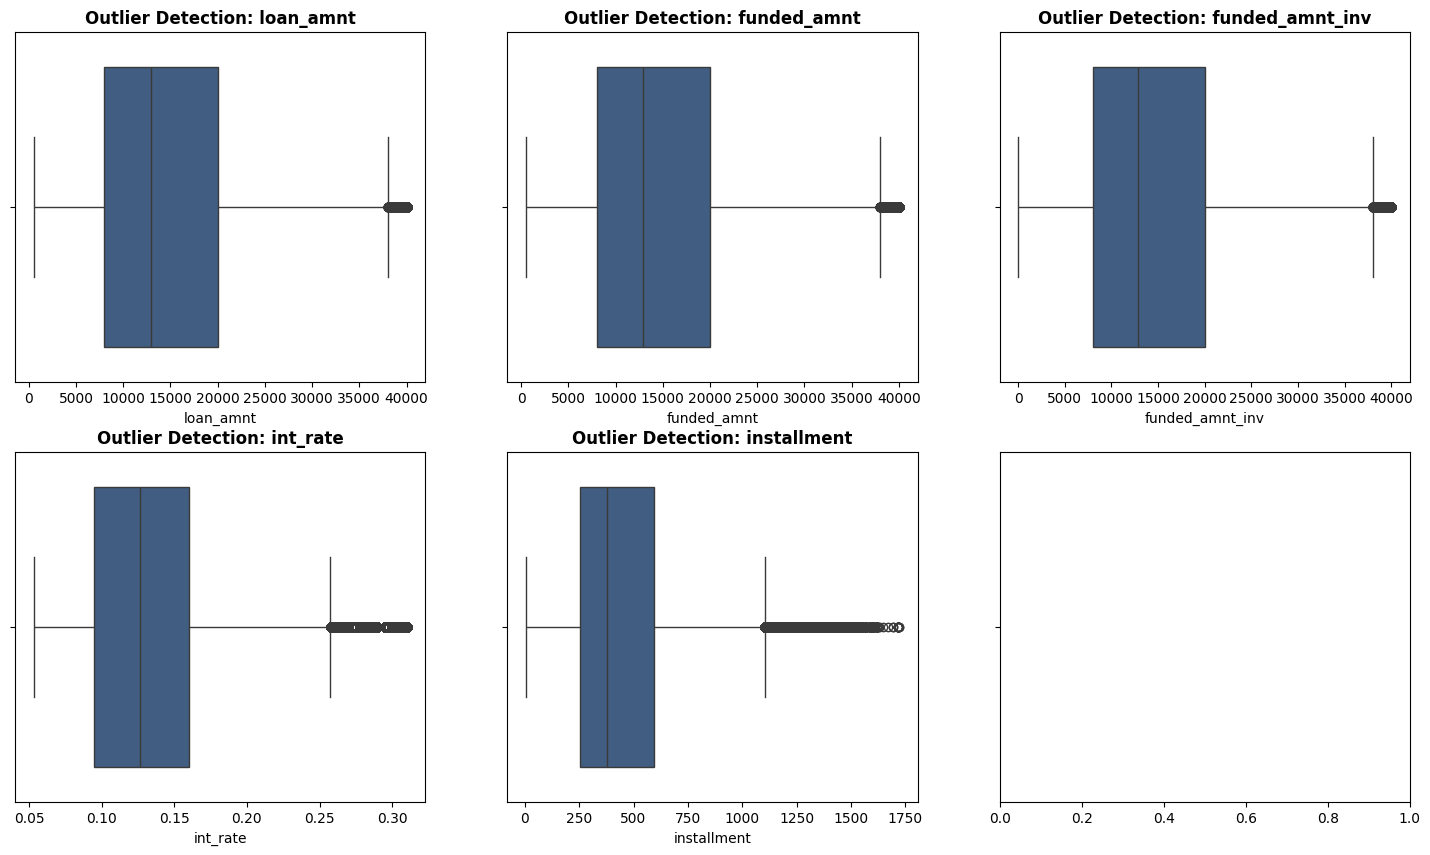

In [16]:
plot_outlier_detection(df_all)

In [ ]:
plot_correlation_matrix(df)

In [ ]:
plot_categorical_feature_distributions(df)

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
import numpy as np

def load_parquet_data(file_path):
    try:
        df = pd.read_parquet(file_path)
        return df
    except Exception as e:
        print(f"Error loading parquet file {file_path}: {e}")
        return None

def plot_outlier_detection(df, output_path="outlier_detection.png"):
    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for idx, col in enumerate(numerical_features):
        if idx < len(axes):
            sns.boxplot(x=df[col], ax=axes[idx], color=sns.color_palette("viridis")[1])
            axes[idx].set_title(f'Outlier Detection: {col}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel(col, fontsize=10)

    plt.tight_layout()
    plt.savefig(output_path)
    plt.close()

def eda_after_processing(df, output_prefix=""):
    if df.empty:
        print(f"Warning: DataFrame is empty for {output_prefix}. Skipping EDA.")
        return

    print("Data Shape (rows, columns):", df.shape)
    print("\nBasic Statistics for Numerical Features:")
    print(df.describe())

    print("\nMissing values in each column:")
    missing_data = df.isnull().sum()
    print(missing_data[missing_data > 0]) 

    if missing_data.any():
        plt.figure(figsize=(12, 6))
        sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
        plt.title("Missing Data Heatmap", fontsize=14, fontweight='bold')
        plt.savefig(f"{output_prefix}_missing_data_heatmap.png")
        plt.close()

    numerical_features = df.select_dtypes(include=['float64', 'int64']).columns
    print(f"\nNumerical features: {list(numerical_features)}")

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()

    for idx, col in enumerate(numerical_features):
        if idx < len(axes):
            df[col].plot(kind='hist', ax=axes[idx], bins=50, alpha=0.7, color=sns.color_palette("viridis")[1], edgecolor='black')
            axes[idx].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel(col, fontsize=10)
            axes[idx].set_ylabel('Frequency', fontsize=10)
            axes[idx].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"{output_prefix}_numerical_features_histograms.png")
    plt.close()

    plot_outlier_detection(df, output_path=f"{output_prefix}_outlier_detection.png")

    plt.figure(figsize=(12, 10))
    correlation_matrix = df[numerical_features].corr()
    sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap="coolwarm", 
                square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
    plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold', pad=20)
    plt.tight_layout()
    plt.savefig(f"{output_prefix}_feature_correlation_matrix.png")
    plt.close()

    correlation_threshold = 0.9
    high_correlation = correlation_matrix.abs() > correlation_threshold
    high_correlation = high_correlation.where(np.triu(np.ones(high_correlation.shape), k=1).astype(bool))
    
    print("\nHighly Correlated Features (above threshold):")
    for col in high_correlation.columns:
        correlated_features = high_correlation[col][high_correlation[col]].index.tolist()
        if len(correlated_features) > 1:
            print(f"{col} is highly correlated with: {', '.join(correlated_features)}")

    categorical_features = df.select_dtypes(include=['object', 'category']).columns
    print(f"\nCategorical features: {list(categorical_features)}")

    for col in categorical_features:
        plt.figure(figsize=(8, 6))
        sns.countplot(x=df[col], palette="viridis")
        plt.title(f'{col} Distribution', fontsize=14, fontweight='bold')
        plt.xlabel(col, fontsize=12)
        plt.ylabel('Count', fontsize=12)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(f"{output_prefix}_{col}_distribution.png")
        plt.close()

    print("\nFeature Engineering Suggestions:")
    for col in categorical_features:
        if df[col].nunique() > 20:  
            print(f"- {col} has {df[col].nunique()} unique categories. Consider encoding methods like OneHot or LabelEncoding.")

    print("\nFeature Scaling Considerations:")
    if 'loan_status_binary' in df.columns:
        print("- Target variable 'loan_status_binary' is binary. Consider using binary encoding or standard scaling on numerical features.")

def process_all_years(base_dir):
    for year_dir in os.listdir(base_dir):
        year_path = os.path.join(base_dir, year_dir)
        
        if os.path.isdir(year_path):  
            print(f"\nProcessing data for year {year_dir}")
            
            for file in os.listdir(year_path):
                if file.endswith('.parquet'):
                    file_path = os.path.join(year_path, file)
                    print(f"Loading data from {file_path}")
                    
                    df = load_parquet_data(file_path)
                    
                    if df is not None:
                        eda_after_processing(df, output_prefix=f"{year_dir}_data")
                    else:
                        print(f"Skipping year {year_dir} due to errors loading the file.")
            
base_dir = '../../preprocessed'

process_all_years(base_dir)



Processing data for year year=2018
Loading data from ../../preprocessed/year=2018/part-00000-450e19c3-d402-4939-ac0b-cdf3b2c16eb1-c000.snappy.parquet
Loading data from ../../preprocessed/year=2018/part-00004-450e19c3-d402-4939-ac0b-cdf3b2c16eb1-c000.snappy.parquet
Data Shape (rows, columns): (495242, 154)

Basic Statistics for Numerical Features:
           loan_amnt    funded_amnt  funded_amnt_inv           term  \
count  495242.000000  495242.000000    495242.000000  495242.000000   
mean    16025.020394   16025.020394     16021.669277      43.296845   
min      1000.000000    1000.000000       725.000000      36.000000   
25%      8000.000000    8000.000000      8000.000000      36.000000   
50%     14000.000000   14000.000000     14000.000000      36.000000   
75%     22000.000000   22000.000000     22000.000000      60.000000   
max     40000.000000   40000.000000     40000.000000      60.000000   
std     10138.075023   10138.075023     10137.900298      11.039954   

          

ValueError: Cannot mask with non-boolean array containing NA / NaN values